# Step 2: Exploratory Data Analysis (EDA)

**Goal:** understand the cleaned data (5 gases, 12,077 samples) before building any model.

We look at: (1) how balanced the gases are, (2) how different the feature scales are, (3) whether the
data has duplicates, constant columns or heavy outliers, and (4) how strongly features are related.

This step is *descriptive only*. We do not tune or select anything here, and no scaler is fitted yet
(that happens in Step 4, on training batches only).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import data_loader as dl
from src import eda

pd.set_option("display.width", 150)
df = dl.remove_toluene(dl.load_all())
GASES = ["Ethanol", "Ethylene", "Ammonia", "Acetaldehyde", "Acetone"]
print("Rows:", len(df), "| feature columns:", len(dl.FEATURE_COLS))

Rows: 12077 | feature columns: 128


## 1. Class balance

In [2]:
overall = df["gas"].value_counts().reindex(GASES)
overall_pct = (overall / overall.sum() * 100).round(1)
pd.DataFrame({"samples": overall, "percent": overall_pct})

,samples,percent
gas,,
Ethanol,2565,21.2
Ethylene,2926,24.2
Ammonia,1641,13.6
Acetaldehyde,1936,16.0
Acetone,3009,24.9


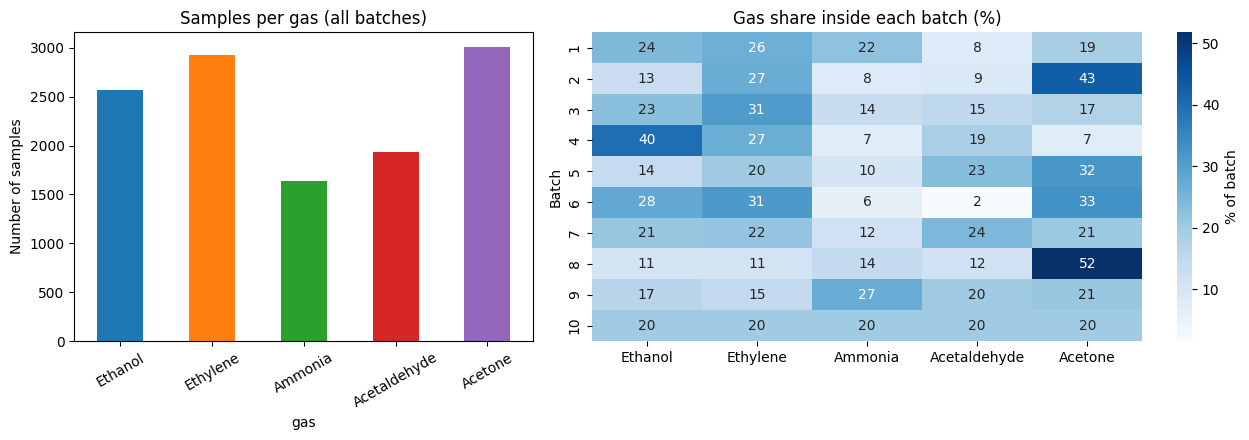

In [3]:
pct = eda.class_percent_per_batch(df)[GASES]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.5]})
overall.plot(kind="bar", ax=axes[0], color=sns.color_palette("tab10")[:5])
axes[0].set_title("Samples per gas (all batches)")
axes[0].set_ylabel("Number of samples")
axes[0].tick_params(axis="x", rotation=30)
sns.heatmap(pct, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar_kws={"label": "% of batch"})
axes[1].set_title("Gas share inside each batch (%)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Batch")
plt.tight_layout()
plt.savefig("../results/step2_gas_balance.png", dpi=150)
plt.show()
pct.round(1).to_csv("../results/step2_class_percent_per_batch.csv")

**What to notice:** overall the five gases are moderately balanced (about 14-25% each: Acetone and Ethylene are
largest, Ammonia smallest). Inside single batches the mix is very different: batch 8 is 52% Acetone, batch 2 is 43%
Acetone, batch 4 is 40% Ethanol, and batch 6 has only 2% Acetaldehyde and 6% Ammonia. Batch 10 is perfectly
balanced (20% each). Because the mix changes from batch to batch, we will report macro-F1 as well as accuracy.

## 2. Do the features have very different scales?

In [4]:
info = eda.feature_info()
summary = eda.type_summary(df)
summary.to_csv("../results/step2_feature_type_summary.csv")
summary.round(3)

,min,median,max,std
type,,,,
dR,-23660.635,12754.371,670687.348,36657.761
norm_dR,0.088,4.002,31165.170,82.378
rise_a0.001,0.000,3.791,169.248,9.675
rise_a0.01,0.000,7.194,730.924,15.583
rise_a0.1,0.000,10.485,12005.619,38.471
decay_a0.001,-131.333,-2.547,0.000,6.738
decay_a0.01,-406.576,-3.924,22.202,11.721
decay_a0.1,-2946.482,-8.984,116.506,72.553


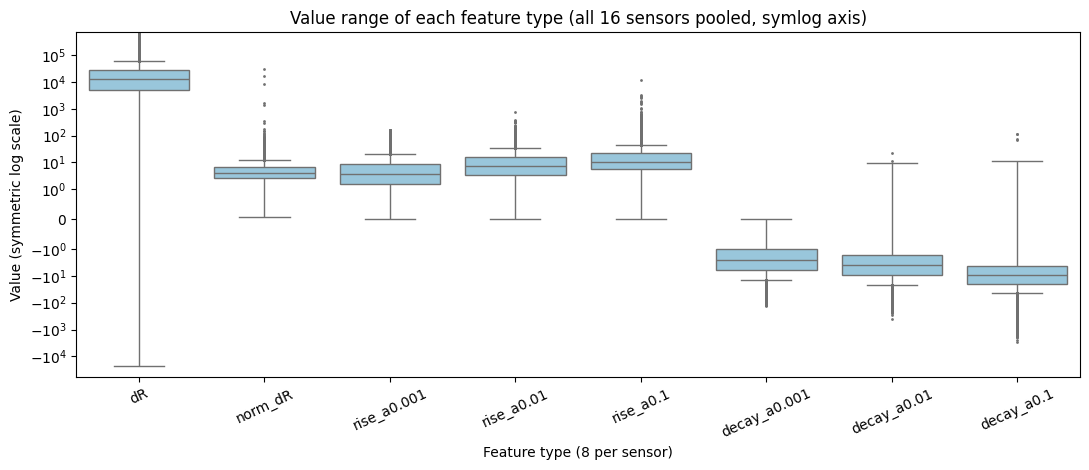

In [5]:
long = []
for t in eda.FEATURE_TYPES:
    cols = info.loc[info["type"] == t, "feature"]
    long.append(pd.DataFrame({"type": t, "value": df[cols].to_numpy().ravel()}))
long = pd.concat(long)

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.boxplot(data=long, x="type", y="value", ax=ax, fliersize=1, color="#8ecae6")
ax.set_yscale("symlog", linthresh=1)
ax.set_title("Value range of each feature type (all 16 sensors pooled, symlog axis)")
ax.set_xlabel("Feature type (8 per sensor)")
ax.set_ylabel("Value (symmetric log scale)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("../results/step2_feature_ranges.png", dpi=150)
plt.show()

Smallest feature std: 0.546 | largest feature std: 73495.5
Ratio largest / smallest: 134515.3


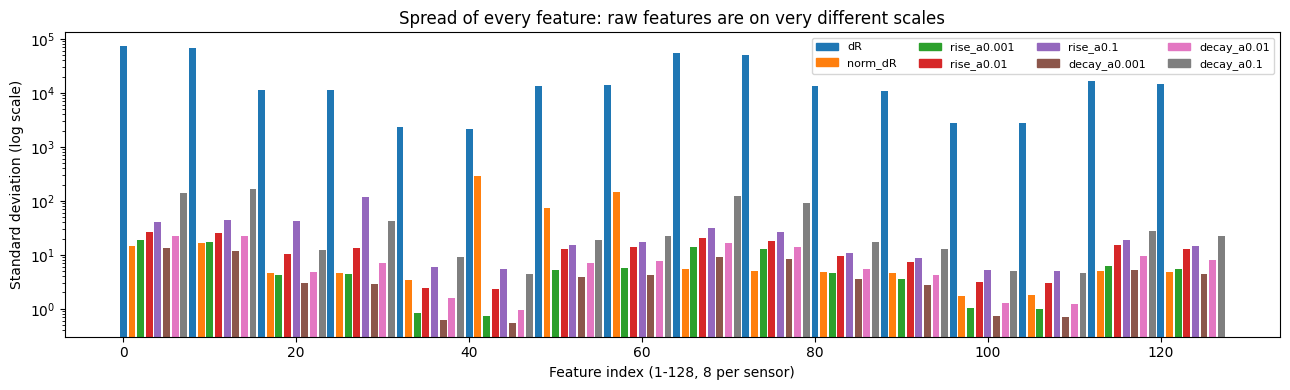

In [6]:
stds = df[dl.FEATURE_COLS].std()
print("Smallest feature std:", round(stds.min(), 3), "| largest feature std:", round(stds.max(), 1))
print("Ratio largest / smallest:", round(stds.max() / stds.min(), 1))

fig, ax = plt.subplots(figsize=(13, 4))
palette = dict(zip(eda.FEATURE_TYPES, sns.color_palette("tab10", 8)))
ax.bar(range(128), stds.values, color=[palette[t] for t in info["type"]])
ax.set_yscale("log")
ax.set_xlabel("Feature index (1-128, 8 per sensor)")
ax.set_ylabel("Standard deviation (log scale)")
ax.set_title("Spread of every feature: raw features are on very different scales")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[t]) for t in eda.FEATURE_TYPES]
ax.legend(handles, eda.FEATURE_TYPES, ncol=4, fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig("../results/step2_feature_std.png", dpi=150)
plt.show()

**What to notice:** the first feature of each sensor (`dR`, the steady-state response) has a typical value
(median) of about 12,800 and spreads over tens of thousands, while the typical value of the other seven features is
only about -9 to 10. The standard deviation of the widest feature is about 134,000 times that of the narrowest.
Models that use distances or margins (kNN, SVM, PCA, LDA) would be dominated by the large-scale features unless
the data is scaled, so scaling (Step 4) is essential.

## 3. Data quality: duplicates, constant columns, outliers, skew

In [7]:
feats = df[dl.FEATURE_COLS]
quality = {
    "duplicate rows": int(feats.duplicated().sum()),
    "constant (zero-variance) features": int((feats.std() == 0).sum()),
    "features with std < 1e-6": int((feats.std() < 1e-6).sum()),
}
print(quality)

skew = feats.skew()
q1, q3 = feats.quantile(0.25), feats.quantile(0.75)
iqr = q3 - q1
outlier_share = ((feats < q1 - 1.5 * iqr) | (feats > q3 + 1.5 * iqr)).mean() * 100
by_type = pd.DataFrame({"median |skew|": skew.abs().groupby(info["type"].values).median(),
                        "mean % outliers (IQR rule)": outlier_share.groupby(info["type"].values).mean()})
by_type.loc[eda.FEATURE_TYPES].round(2)

{'duplicate rows': 0, 'constant (zero-variance) features': 0, 'features with std < 1e-6': 0}


,median |skew|,mean % outliers (IQR rule)
dR,1.17,3.30
norm_dR,4.04,6.24
rise_a0.001,1.25,3.54
rise_a0.01,1.87,3.72
rise_a0.1,4.00,3.86
decay_a0.001,1.63,3.37
decay_a0.01,2.78,4.09
decay_a0.1,6.88,5.77


**What to notice:** the table shows how skewed each feature type is and how many points fall outside the
usual range (the 1.5 x IQR rule). Many features are skewed with long tails. We keep these points: in sensor data
large values are real responses to higher gas concentrations, not errors, so we do not delete outliers.

## 4. Are the features related to each other?

Share of feature pairs with |correlation| > 0.9: 6.3%


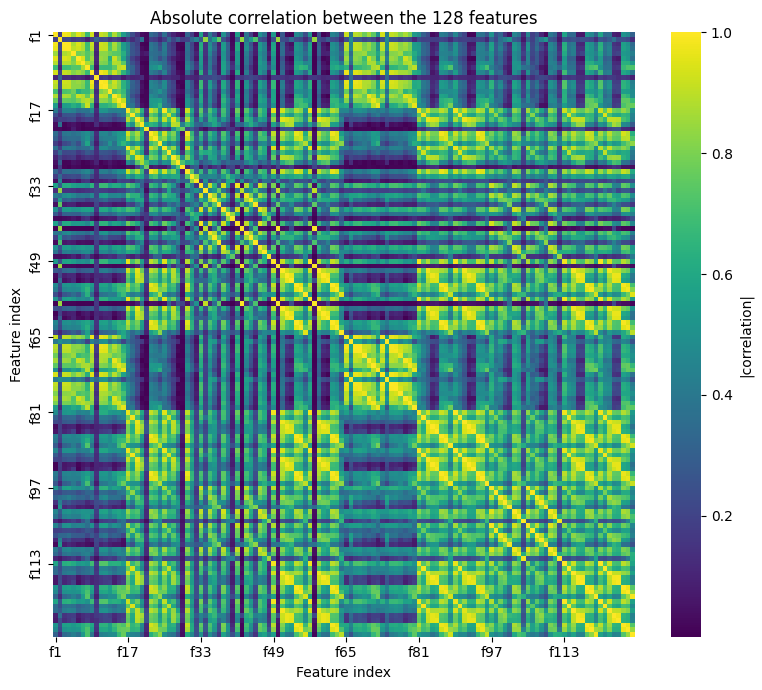

In [8]:
corr = feats.corr()
share = eda.high_correlation_share(df, 0.9)
print(f"Share of feature pairs with |correlation| > 0.9: {share * 100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr.abs(), cmap="viridis", ax=ax, xticklabels=16, yticklabels=16,
            cbar_kws={"label": "|correlation|"})
ax.set_title("Absolute correlation between the 128 features")
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
plt.tight_layout()
plt.savefig("../results/step2_correlation.png", dpi=150)
plt.show()

**What to notice:** the heatmap has clear block patterns, so many features move together (bright yellow/green
areas), for example features of the same type across different sensors. But only 6.3% of feature pairs have
|correlation| above 0.9, so the overlap is partial, not total. This suggests PCA/LDA (Step 6) may be able to compress
the 128 features, but whether that helps accuracy and drift robustness will be tested, not assumed.

## 5. Summary of Step 2

In [9]:
print("Samples:", len(df), "| gases:", df["gas"].nunique(), "| batches:", df["batch"].nunique())
print("Duplicates:", quality["duplicate rows"], "| constant features:", quality["constant (zero-variance) features"])
print(f"Std ratio (largest/smallest feature): {stds.max() / stds.min():.0f}")
print(f"Highly correlated feature pairs (|r|>0.9): {share * 100:.1f}%")

Samples: 12077 | gases: 5 | batches: 10
Duplicates: 0 | constant features: 0
Std ratio (largest/smallest feature): 134515
Highly correlated feature pairs (|r|>0.9): 6.3%
